<a href="https://colab.research.google.com/github/nrannisak2/2026_Intro_Python/blob/main/FEEDBACK_NURANNISA_Exercise_Env_1_4_matplotlib_and_xarray_environmental_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.4-matplotlib-and-xarray-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

## Compelling Challenge

Visualization is my favourite part of Python programming, but it is also one of the areas I struggle with the most. While working through this exercise, I encountered several bugs and challenges in reproducing the provided visualizations, particularly in **Exercises 2 and 3.**

The two Markdown files corresponding to the questions which code answers produced unexpected errors are available on the page below.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Run the setup cell below first. Label every axis with its unit.

Exercise 1 works on a real global-temperature record, and the last four exercises work differently: each shows a figure made from a real dataset and asks you to rebuild it. Get as close as you can, and read the hints one at a time rather than all at once.

In [2]:
# Pre-supplied: run this first.
import numpy as np
import matplotlib.pyplot as plt

## Replicating plots

The four exercises below each show a figure built from a real dataset and ask you to rebuild it
as closely as you can. The data arrive through a pre-supplied `pooch` cell; everything after that
is yours.

Work towards the target one element at a time — get the data onto the axes first, then the
coordinates, then the colours, then the labels — rather than trying to write the whole cell in
one go.

## Exercise 1: NASA's real global-temperature record

The file cached below is NASA GISS's monthly global-mean surface temperature anomaly (°C,
relative to a 1951–1980 baseline), one row per year since 1880, one column per calendar month.
A handful of recent months are still missing, marked `***`.

Wrap the twelve month columns in an xarray `DataArray` with dims `("year", "month")` and a `units`
attribute, then draw two figures: the annual mean as a line against year, and the full
`(year, month)` array with xarray's own `.plot()`. In a comment, compare what the warming trend
looks like read month by month against the single annual line.

In [3]:
# Pre-supplied: download the data file and cache it locally.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/nasa_gistemp_global_temp_anomaly.csv",
    known_hash="sha256:6cfa44e7bbacd9b12cb10bdd64b3182c2735fa3f3a95688e1f7bc8e5dfcece93",
    fname="nasa_gistemp_global_temp_anomaly.csv",
    path=pooch.os_cache("mlees"),
)

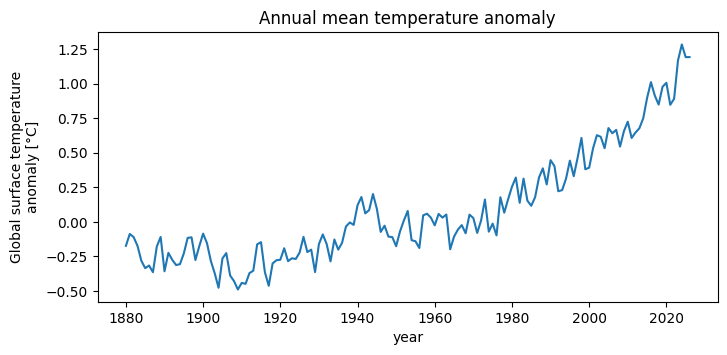

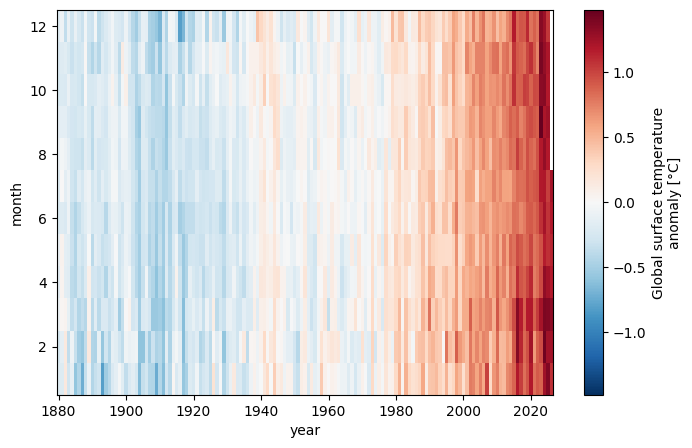

In [4]:
# Your solution here
import xarray as xr

# Hint: load the file with
data = np.genfromtxt(path, skip_header=1, delimiter=",", names=True,
              missing_values="***", filling_values=np.nan)

#       -- names=True reads the header row, so the columns are data["Year"], data["Jan"], ...

values = np.column_stack((data["Jan"], data["Feb"], data["Mar"], data["Apr"], data["May"],
                 data["Jun"], data["Jul"], data["Aug"], data["Sep"], data["Oct"],
                 data["Nov"], data["Dec"]))

# Hint: the coordinates are data["Year"] and np.arange(1, 13)

df      = xr.DataArray(
          values,
          dims=("year", "month"),
          coords={"year": data["Year"],
                  "month": np.arange(1,13)},
          attrs={"long_name": "Global surface temperature anomaly",
                 "units": "°C"}
)

# Hint: .mean(dim="month") skips the missing months on its own
annual_mean = df.mean(dim="month")
fig, ax = plt.subplots(figsize=(8, 3.5))
annual_mean.plot(ax=ax)
ax.set_title("Annual mean temperature anomaly")
plt.show()

# Hint: .plot() on the 2D DataArray draws a pcolormesh, and labels the colorbar from the
#       long_name and units attributes

fig, ax = plt.subplots(figsize=(8,5))
df.plot(x="year", ax=ax)
plt.show()

## Exercise 2: Global surface air temperature and its zonal mean

The three files cached below hold one snapshot of surface air temperature from the
[NCEP/NCAR atmospheric reanalysis 1](https://psl.noaa.gov/data/gridded/data.ncep.reanalysis.html),
as plain numpy arrays: `lon` (192 longitudes), `lat` (94 latitudes, running north to south), and
`temp_kelvin`, the field itself with shape `(94, 192)` — **in kelvin**.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-global-temperature.png" alt="A filled contour map of global surface air temperature in magma colours with a white dashed contour at minus ten degrees, beside a line plot of the zonal mean against latitude" width="100%">

<em>The figure to replicate. Left: the field as filled contours, with a single white contour drawn
at −10 °C. Right: the zonal mean — the average along longitude — against latitude.</em>


Rebuild it, and say in a comment which hemisphere's winter this snapshot was taken in, and how
the zonal mean tells you.

## **Challenge: global surface temperature plot did not map the reference.**

In the first version:
* I drew `imshow` together with `contourf` (copied the codes from another assignment), where imshow uses pixel indices (and flips the y-axis), so the map was shown in the wrong coordinates, partially cropped and upside down, and the colorbar came from imshow instead of from the contour plot. In addition, only part of the world is visible. The southern hemisphere and everything else outside the pixel window are cut off.
* For the surface-temperature figure I wanted a filled contour map with a dashed white line at -10 °C, next to a zonal-mean profile. My first attempt gave a map that was cropped, upside down and colored with the wrong colorbar, and it had no white line. There is no dashed white line. `contour_level=[-10]` isn’t a valid argument, (In current matplotlib the invalid keyword raises an `AttributeError`.) so it does nothing. The -10 °C line needs its own `ax[0].contour(...)` call.

The fix:
* Remove `imshow`, add a separate contour call for the `levels=[-10]` °C line, and build the colorbar from the `contourf` result.

In [5]:
# Pre-supplied: download the three arrays and cache them locally.
import pooch

In [6]:
base_url = "https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/"

In [7]:
path_lon = pooch.retrieve(
    url=base_url + "ncep_global_temp_lon.npy",
    known_hash="sha256:eaf54b88dd89279d3034da17fe8470dc2c841bf9fa89b2aa741dacff9c326cdb",
    fname="ncep_global_temp_lon.npy",
    path=pooch.os_cache("mlees"),
)
path_lat = pooch.retrieve(
    url=base_url + "ncep_global_temp_lat.npy",
    known_hash="sha256:af1f438080460e1fca4583b2ec19b44285a3d3776e4d21b8da9b6e162906c88a",
    fname="ncep_global_temp_lat.npy",
    path=pooch.os_cache("mlees"),
)
path_temp = pooch.retrieve(
    url=base_url + "ncep_global_temp_kelvin.npy",
    known_hash="sha256:e040ca257334708b43e86398e09a5669fcf051179ecf5dcd278f758d67beed20",
    fname="ncep_global_temp_kelvin.npy",
    path=pooch.os_cache("mlees"),
)

/tmp/ipykernel_949/3699699989.py:9: UserWarning: The following kwargs were not used by contour: 'contour_level'
  ax[0].contourf(lon, lat, temp_c, levels=np.linspace(-30, 40, 15), cmap="magma", extend="both",


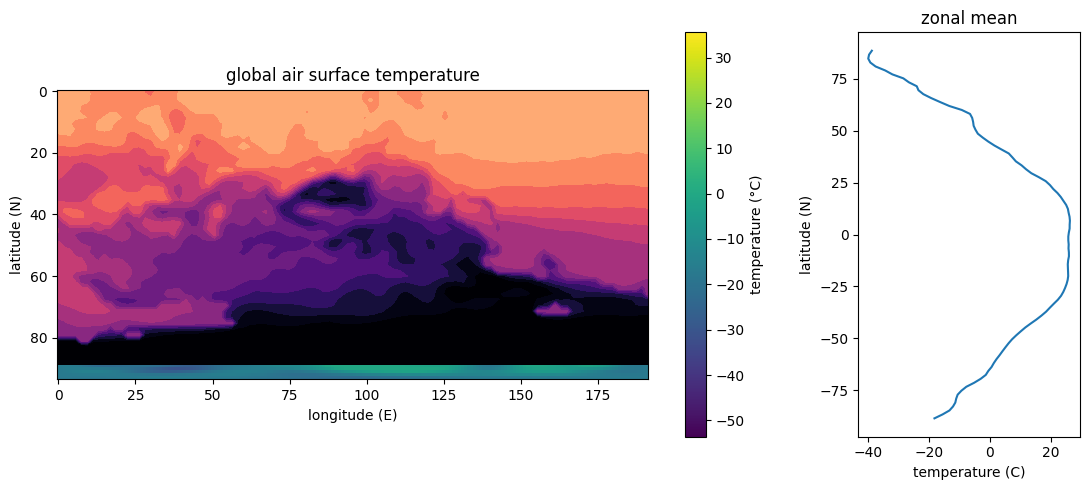

In [8]:
# Your solution here (wrong codes)
lon = np.load(path_lon)
lat = np.load(path_lat)
temp = np.load(path_temp)
temp_c = temp.astype(float) - 273.15

fig, ax = plt.subplots(1, 2, figsize = (11, 5), gridspec_kw={"width_ratios": [5, 1.5]})

ax[0].contourf(lon, lat, temp_c, levels=np.linspace(-30, 40, 15), cmap="magma", extend="both",
               contour_level=[-10]) # error countour_level
im = ax[0].imshow(temp_c) # should not use imshow
fig.colorbar(im, ax=ax[0], label="temperature (°C)")

ax[1].plot(np.mean(temp_c, axis=1), lat)

ax[0].set_xlabel("longitude (E)")
ax[0].set_ylabel("latitude (N)")
ax[0].set_title("global air surface temperature")

ax[1].set_xlabel("temperature (C)")
ax[1].set_ylabel("latitude (N)")
ax[1].set_title("zonal mean")

plt.tight_layout()

<function matplotlib.pyplot.show(close=None, block=None)>

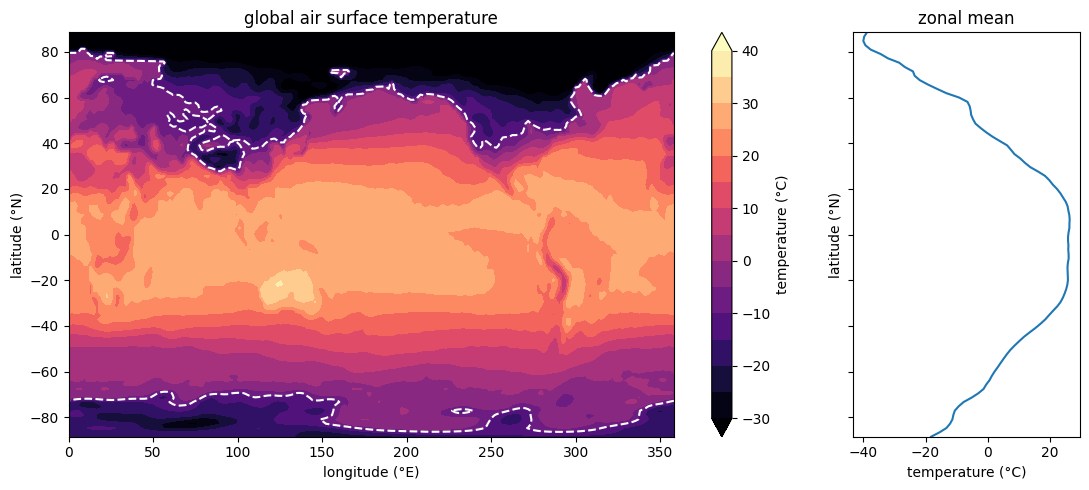

In [9]:
# Your solution here (corrected codes)
lon = np.load(path_lon)
lat = np.load(path_lat)
temp = np.load(path_temp)
temp_c = temp.astype(float) - 273.15

fig, ax = plt.subplots(1, 2, figsize = (11, 5),
                       gridspec_kw={"width_ratios": [5, 1.5]},
                       sharey=True)

cf = ax[0].contourf(lon, lat, temp_c, levels=np.linspace(-30, 40, 15),
                    cmap="magma", extend="both") # use contourf only, without adding im
ax[0].contour(lon, lat, temp_c, levels=[-10], colors="w")
fig.colorbar(cf, ax=ax[0], label="temperature (°C)")

ax[1].plot(np.mean(temp_c, axis=1), lat)

ax[0].set_xlabel("longitude (°E)")
ax[0].set_ylabel("latitude (°N)")
ax[0].set_title("global air surface temperature")

ax[1].set_xlabel("temperature (°C)")
ax[1].set_ylabel("latitude (°N)")
ax[1].set_title("zonal mean")

plt.tight_layout()
plt.show

## Exercise 3: Historic significant earthquakes

The file cached below is NOAA's catalog of significant earthquakes, reaching back to 2150 BCE:
one row per event, tab-separated, 47 columns. The four you need are at positions 8
(`FOCAL_DEPTH`, km), 9 (`EQ_PRIMARY`, magnitude), 20 (`LATITUDE`) and 21 (`LONGITUDE`).

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-earthquakes-scatter.png" alt="A scatter plot of earthquake longitude against latitude, coloured by the base-10 logarithm of focal depth and sized by magnitude" width="100%">

<em>The figure to replicate: every event as one point, coloured by the base-10 logarithm of its
focal depth and sized by its magnitude. No coastline is drawn — the plate boundaries are the
data.</em>


Rebuild it, and in a comment name the feature of the Earth that the points trace out.

## **Challenge: the earthquake map did not match the reference figure**

Main problem: the figure had no title, no axis labels and no grid, and an extra empty figure appeared below it.

The cause:
* Because `plt.scatter(...)` and `plt.colorbar(...)` draw on the *current* figure, `plt.figure(figsize=(10, 6))` and `plt.subplots()` each opened a
*new* figure and made it current.
* The title, labels and grid were therefore applied to the last, empty figure, while the points stayed on the first one without any decoration, and the `figsize` went to a figure that never got any data.
* Therefore: the axis labels were swapped and mislabelled, the points were opaque while the reference uses transparency (`alpha`), and the title wording differed.


The fix:
* Create the figure and axes first and call `ax.scatter`, `fig.colorbar` and `ax.set_...` on that same `ax`, so everything ends up in a single figure.

In [10]:
# Pre-supplied: download the data file and cache it locally.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/signif.txt.tsv",
    known_hash="sha256:f27e00d335f64ffaf437e74a8efb54f9154d40b417ff93fefb0fd64856e6d345",
    fname="signif.txt.tsv",
    path=pooch.os_cache("mlees"),
)

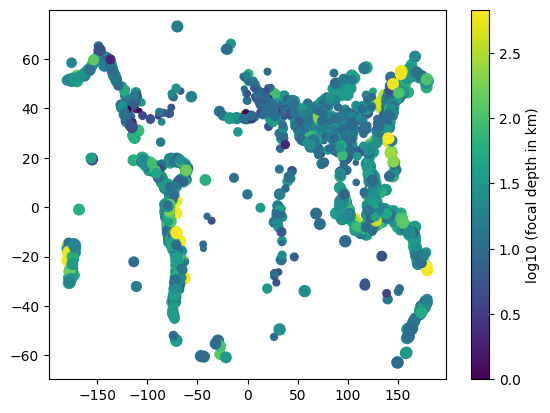

<Figure size 1000x600 with 0 Axes>

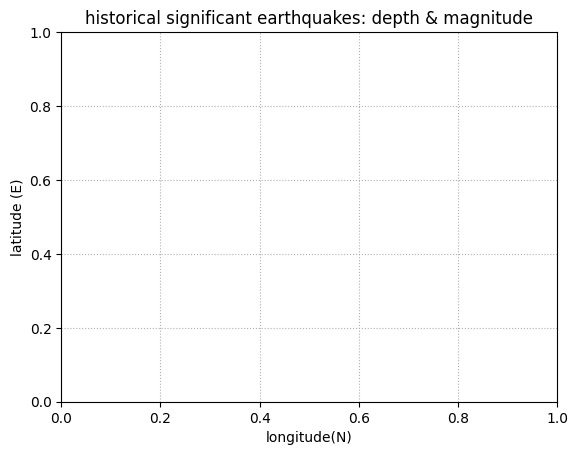

In [11]:
# Your solution here (codes with bugs)

arr = np.genfromtxt(path, delimiter="\t", skip_header=1)

# pull all 4 columns
depth = arr[:, 8]
mag = arr[:, 9]
lat = arr[:, 20]
lon = arr[:, 21]

mask = (depth > 0) & (mag > 0) & ~np.isnan(lat) & ~np.isnan(lon)
depth = depth[mask]
mag = mag[mask]
lat = lat[mask]
lon = lon[mask]


sc = plt.scatter(
    lon, lat,
    c=np.log10(depth), # colour the point
    s=mag**2 # point area

)

cbar = plt.colorbar(sc)
cbar.set_label("log10 (focal depth in km)")

plt.figure(figsize=(10,6))
fig, ax = plt.subplots()
ax.set_xlabel("longitude(N)")
ax.set_ylabel("latitude (E)")
ax.set_title("historical significant earthquakes: depth & magnitude")
ax.grid(True, linestyle=':')
plt.show()

<Figure size 1000x600 with 0 Axes>

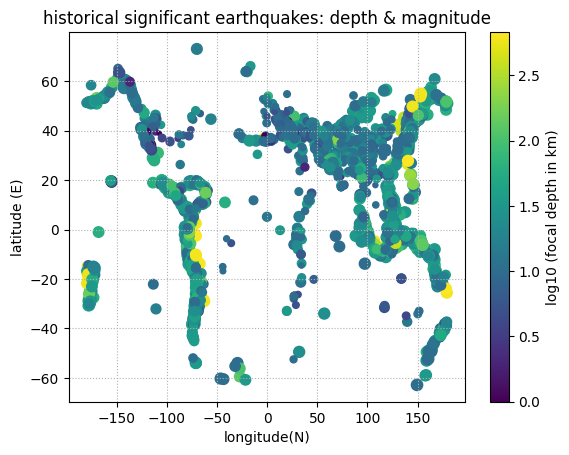

In [12]:
# Your solution here (corrected codes)

arr = np.genfromtxt(path, delimiter="\t", skip_header=1)

# pull all 4 columns
depth = arr[:, 8]
mag = arr[:, 9]
lat = arr[:, 20]
lon = arr[:, 21]

mask = (depth > 0) & (mag > 0) & ~np.isnan(lat) & ~np.isnan(lon)
depth = depth[mask]
mag = mag[mask]
lat = lat[mask]
lon = lon[mask]

plt.figure(figsize=(10,6))
fig, ax = plt.subplots()
sc = plt.scatter(
    lon, lat,
    c=np.log10(depth), # colour the point
    s=mag**2 # point area

)

cbar = plt.colorbar(sc)
cbar.set_label("log10 (focal depth in km)")

ax.set_xlabel("longitude(N)")
ax.set_ylabel("latitude (E)")
ax.set_title("historical significant earthquakes: depth & magnitude")
ax.grid(True, linestyle=':')
plt.show()

## Exercise 4: Antarctic sea ice, summer against winter

Two real snapshots of Antarctic sea ice concentration from NOAA/NSIDC are cached below, as
`path_winter` (1 August 2017) and `path_summer` (31 December 2017). Each holds
`seaice_conc_cdr`, the ice concentration as a fraction from 0 to 1, on a south polar
stereographic grid — its coordinates are 2D `latitude`/`longitude` arrays rather than simple 1D
dimensions, so xarray's own `.plot()` will not label it cleanly.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-seaice.png" alt="Two south polar stereographic maps of Antarctic sea ice concentration, one in austral winter with a wide ice ring and one in austral summer with much less ice" width="100%">

<em>The figure to replicate: the same field on the same projection at two dates, with the land drawn
in grey beneath the ice and one colorbar shared by both panels.</em>


Rebuild it, and say which date shows more ice.

In [13]:
# Pre-supplied: download the data files and cache them locally.
import pooch

path_winter = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/seaice_conc_daily_sh_f17_20170801_v03r01.nc",
    known_hash="sha256:1ff50bca1e6249a9b2fcd9d9466e31bdb5be650243f99c7319ab2ce625b87ce7",
    fname="seaice_conc_daily_sh_f17_20170801_v03r01.nc",
    path=pooch.os_cache("mlees"),
)
path_summer = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/seaice_conc_daily_sh_f17_20171231_v03r01.nc",
    known_hash="sha256:309418969ad09f42b8104589bcb86de4ed353a5742fef9385baec174c7d55e66",
    fname="seaice_conc_daily_sh_f17_20171231_v03r01.nc",
    path=pooch.os_cache("mlees"),
)

In [17]:
!pip install cartopy
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 27.3 MB/s  0:00:00


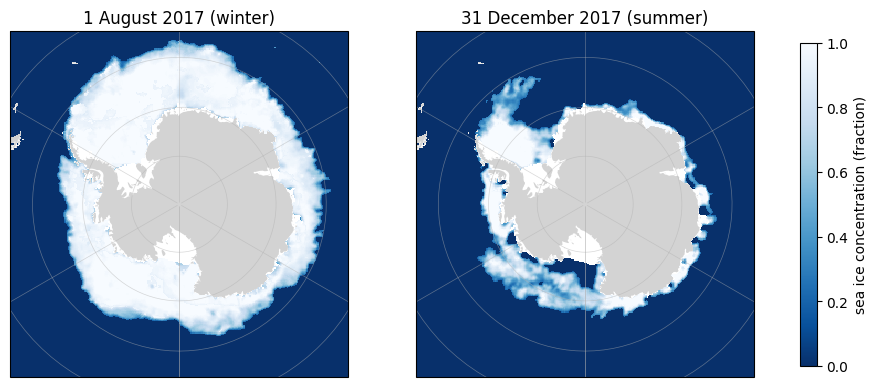

winter: 27224 ice-covered cells
summer: 10413 ice-covered cells


In [22]:
# Your solution here
# Hint: open each file with xr.open_dataset and select the single time step with .isel(time=0)
ds_winter = xr.open_dataset(path_winter).isel(time=0)
ds_summer = xr.open_dataset(path_summer).isel(time=0)

# Hint: the valid concentration range is 0-1; a few cells carry flag values above 1
#       (land, coastal, missing) -- mask them out first with da.where(da <= 1)
conc_winter = ds_winter["seaice_conc_cdr"]
conc_summer = ds_summer["seaice_conc_cdr"]
masked_winter = conc_winter.where(conc_winter <= 1)
masked_summer = conc_summer.where(conc_summer <= 1)

# Hint: build a figure with two ccrs.SouthPolarStereo() axes:
#       plt.subplots(1, 2, subplot_kw={"projection": ccrs.SouthPolarStereo()})

fig, axes = plt.subplots(
    1, 2, figsize=(12, 6), subplot_kw={"projection": ccrs.SouthPolarStereo()},
)

panels = [
    (axes[0], ds_winter, masked_winter, "1 August 2017 (winter)"),
    (axes[1], ds_summer, masked_summer, "31 December 2017 (summer)"),
]

# Hint: ax.set_extent([-180, 180, -90, -55], ccrs.PlateCarree()) crops each axes to the
#       Southern Ocean instead of the whole hemisphere

for ax, ds, masked, title in panels:
    # Hint: set_extent crops each axes to the Southern Ocean
    ax.set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=0)


# Hint: since latitude/longitude are 2D, plot with
#       ax.pcolormesh(ds["longitude"], ds["latitude"], masked, transform=ccrs.PlateCarree())
#       rather than xarray's own .plot()
# Hint: pass vmin=0 and vmax=1 to both pcolormesh calls, so a colour means the same
#       concentration in both panels and one colorbar can serve both
    pcm = ax.pcolormesh(
        ds["longitude"], ds["latitude"], masked,
        transform=ccrs.PlateCarree(),
        vmin=0, vmax=1, cmap="Blues_r", zorder=1,
    )

    ax.gridlines(linewidth=0.5, alpha=0.5)
    ax.set_title(title)

fig.colorbar(pcm, ax=axes, label="sea ice concentration (fraction)", shrink=0.7)
plt.show()

for title, masked in [("winter", masked_winter), ("summer", masked_summer)]:
    n_cells = int((masked >= 0.15).sum())
    print(f"{title}: {n_cells} ice-covered cells")
# Hint: add cfeature.LAND under the data and gridlines; fig.colorbar(pcm, ax=axes, label=...)
#       takes the whole array of axes and draws one colorbar for both panels

from matplotlib.patches import Patch

cmap = plt.get_cmap("Blues_r")
handles = [
    Patch(facecolor=cmap(0.0), edgecolor="k", label="Open water (0%)"),
    Patch(facecolor=cmap(0.5), edgecolor="k", label="Partial ice cover (~50%)"),
    Patch(facecolor=cmap(1.0), edgecolor="k", label="Full ice cover (100%)"),
    Patch(facecolor="lightgrey", edgecolor="k", label="Land"),
]

fig.legend(handles=handles, loc="lower center", ncol=4,
           title="Sea ice concentration", frameon=True)

1 August 2017 (winter) should show more ice. In the Southern Hemisphere, August is late winter and the ice is near its yearly maximum. Late December is summer, when the ice has retreated.

However, the result is not entirely similar to the reference, this due to the legend location at the right part of the graph. But the information is the same.

## Exercise 5: The 2014 earthquakes over North America

The file cached below is the real USGS earthquake catalog for 2014 — one row per event
worldwide, with latitude, longitude, depth and magnitude in columns 1 to 4. The target figure
keeps the whole catalog and lets the map extent do the selecting, so what you see is a window
onto a global dataset rather than one cropped to North America in advance.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-earthquakes-map.png" alt="A Robinson-projection map of North America with state boundaries, lakes and rivers, and earthquake locations coloured by depth" width="90%">

<em>The figure to replicate: magnitude 4 and above, on a Robinson projection cropped to North and
Central America, over land, ocean, lake, river and state-boundary features.</em>


Rebuild it.

In [23]:
# Pre-supplied: download the data file and cache it locally.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/usgs_earthquakes_2014.csv",
    known_hash="sha256:84d455fb96dc8f782fba4b5fbe56cb8970cab678f07c766fcba1b1c4674de1b1",
    fname="usgs_earthquakes_2014.csv",
    path=pooch.os_cache("mlees"),
)

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_rivers_lake_centerlines.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Do

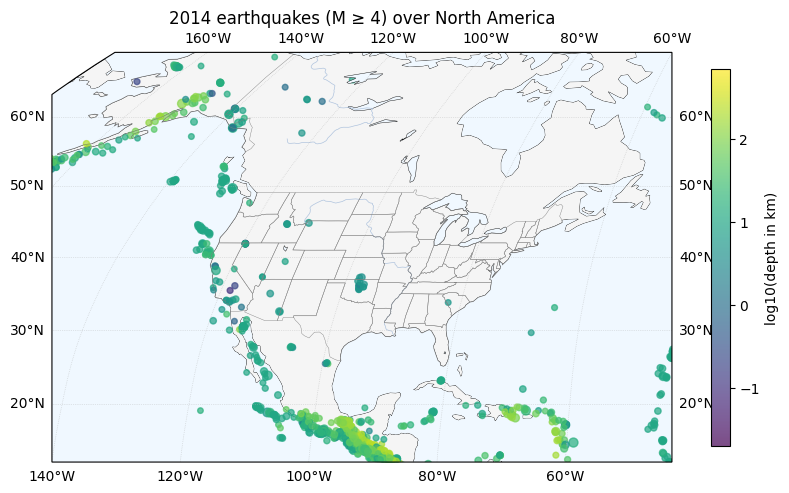

In [24]:
# Hint: load the four numeric columns with
#       np.genfromtxt(path, delimiter=",", skip_header=1, usecols=(1, 2, 3, 4))
#       -- usecols skips the text columns (time, place, ...) mixed in with the numbers
data = np.genfromtxt(path, delimiter=",", skip_header=1, usecols=(1, 2, 3, 4))
lat, lon, depth_km, mag = data.T

# Hint: keep mag >= 4 and depth_km > 0 (a few events are recorded at exactly 0 km, which
#       np.log10 cannot take); combine the two conditions into one mask with & ("and")
mask = (mag >= 4) & (depth_km > 0)

# Hint: fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()})
fig, ax = plt.subplots(figsize=(10, 7), subplot_kw={"projection": ccrs.Robinson()})

# Hint: ax.set_extent([-140, -60, 12, 70], ccrs.PlateCarree()) crops to the window shown
ax.set_extent([-140, -60, 12, 70], ccrs.PlateCarree())
lat, lon, depth_km, mag = lat[mask], lon[mask], depth_km[mask], mag[mask]

# Hint: the features are cfeature.LAND, cfeature.OCEAN, cfeature.LAKES, cfeature.RIVERS and
#       cfeature.STATES; add_feature takes edgecolor, facecolor and linewidth, and STATES
#       reads better in gray at a thin linewidth
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", edgecolor="black", linewidth=0.5)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
ax.add_feature(cfeature.LAKES, facecolor="aliceblue", edgecolor="black", linewidth=0.3)
ax.add_feature(cfeature.RIVERS, edgecolor="lightsteelblue", linewidth=0.5)
ax.add_feature(cfeature.STATES, edgecolor="gray", facecolor="none", linewidth=0.3)

# Hint: ax.scatter(longitude, latitude, transform=ccrs.PlateCarree(),
#                  c=np.log10(depth_km), s=mag ** 2)
sc = ax.scatter(
    lon, lat,
    transform=ccrs.PlateCarree(),   # coordinates are plain lon/lat, not projected
    c=np.log10(depth_km),           # colour = log10 of depth
    s=mag ** 2,                     # area = magnitude squared
    alpha=0.7,
)

#       -- transform tells cartopy the coordinates are plain lon/lat, not already projected

# Hint: finish with ax.gridlines, a labelled colorbar, and a title
ax.gridlines(draw_labels=True, linewidth=0.5, linestyle=":", alpha=0.6)
fig.colorbar(sc, ax=ax, label="log10(depth in km)", shrink=0.7)
ax.set_title("2014 earthquakes (M ≥ 4) over North America")
plt.show()